# VELV + VV Joint Pattern Analysis (R3)

This notebook analyzes **VELVETFRUIT_EXTRACT** and the full **VEV strike ladder** together to identify cross-product patterns.

Policy used here: **day 2 is excluded** to keep it held out for backtest validation.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style='whitegrid', context='talk')
plt.rcParams['figure.figsize'] = (16, 6)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

def find_data_dir() -> Path:
    for candidate in (Path('R3/Data'), Path('../Data'), Path('Data')):
        if candidate.exists():
            return candidate
    raise FileNotFoundError('Could not find R3/Data from the current notebook location.')

DATA_DIR = find_data_dir()
HOLDOUT_DAY = 2
VELV = 'VELVETFRUIT_EXTRACT'

price_files = [p for p in sorted(DATA_DIR.glob('prices_round_3_day_*.csv')) if int(p.stem.split('_day_')[-1]) != HOLDOUT_DAY]
trade_files = [p for p in sorted(DATA_DIR.glob('trades_round_3_day_*.csv')) if int(p.stem.split('_day_')[-1]) != HOLDOUT_DAY]

prices = pd.concat([pd.read_csv(p, sep=';') for p in price_files], ignore_index=True)
trades = pd.concat([pd.read_csv(p, sep=';').assign(day=int(p.stem.split('_day_')[-1])) for p in trade_files], ignore_index=True)

vv_symbols = sorted([s for s in prices['product'].unique().tolist() if s.startswith('VEV_')])

print('Data dir:', DATA_DIR)
print('Holdout day:', HOLDOUT_DAY)
print('In-sample price files:', [p.name for p in price_files])
print('In-sample trade files:', [p.name for p in trade_files])
print('VV symbols:', vv_symbols)

Data dir: ../Data
Holdout day: 2
In-sample price files: ['prices_round_3_day_0.csv', 'prices_round_3_day_1.csv']
In-sample trade files: ['trades_round_3_day_0.csv', 'trades_round_3_day_1.csv']
VV symbols: ['VEV_4000', 'VEV_4500', 'VEV_5000', 'VEV_5100', 'VEV_5200', 'VEV_5300', 'VEV_5400', 'VEV_5500', 'VEV_6000', 'VEV_6500']


In [2]:
# Build base VELV book features
velv = prices.loc[prices['product'] == VELV].copy().sort_values(['day', 'timestamp'])
velv['velv_spread'] = velv['ask_price_1'] - velv['bid_price_1']
velv['velv_imbalance'] = (velv['bid_volume_1'] - velv['ask_volume_1']) / (velv['bid_volume_1'] + velv['ask_volume_1'])
velv['velv_ret'] = velv.groupby('day')['mid_price'].diff()
velv = velv.rename(columns={'mid_price': 'velv_mid'})

vv_prices = prices.loc[prices['product'].isin(vv_symbols)].copy()
vv_trades = trades.loc[trades['symbol'].isin(vv_symbols)].copy()

print('VELV rows:', len(velv))
print('VV price rows:', len(vv_prices))
print('VV trade rows:', len(vv_trades))

VELV rows: 20000
VV price rows: 200000
VV trade rows: 1121


In [3]:
def strike_from_symbol(symbol: str) -> int:
    return int(symbol.split('_')[1])

def day_safe_corr(df: pd.DataFrame, x: str, y: str) -> float:
    v = df[[x, y]].dropna()
    if len(v) < 20:
        return np.nan
    if np.isclose(v[x].std(ddof=0), 0) or np.isclose(v[y].std(ddof=0), 0):
        return np.nan
    return v[x].corr(v[y])

rows = []
for s in vv_symbols:
    strike = strike_from_symbol(s)
    p = vv_prices.loc[vv_prices['product'] == s].copy().sort_values(['day', 'timestamp'])
    t = vv_trades.loc[vv_trades['symbol'] == s].copy()

    p['vv_spread'] = p['ask_price_1'] - p['bid_price_1']
    p['vv_imbalance'] = (p['bid_volume_1'] - p['ask_volume_1']) / (p['bid_volume_1'] + p['ask_volume_1'])
    p = p.rename(columns={'mid_price': 'vv_mid'})

    m = p.merge(velv[['day', 'timestamp', 'velv_mid', 'velv_ret', 'velv_spread', 'velv_imbalance']], on=['day', 'timestamp'], how='left')
    m = m.sort_values(['day', 'timestamp'])

    m['vv_ret'] = m.groupby('day')['vv_mid'].diff()
    m['intrinsic'] = (m['velv_mid'] - strike).clip(lower=0)
    m['time_value_proxy'] = m['vv_mid'] - m['intrinsic']

    valid = m[['vv_ret', 'velv_ret']].dropna()
    if len(valid) > 20 and valid['velv_ret'].abs().sum() > 0:
        beta = np.polyfit(valid['velv_ret'], valid['vv_ret'], 1)[0]
        corr_0 = valid['vv_ret'].corr(valid['velv_ret'])
        corr_m1 = valid['vv_ret'].corr(valid['velv_ret'].shift(1))
        corr_p1 = valid['vv_ret'].corr(valid['velv_ret'].shift(-1))
    else:
        beta = np.nan
        corr_0 = np.nan
        corr_m1 = np.nan
        corr_p1 = np.nan

    m['vv_next'] = m.groupby('day')['vv_mid'].shift(-1) - m['vv_mid']
    imb_signal = day_safe_corr(m, 'vv_imbalance', 'vv_next')

    rows.append({
        'symbol': s,
        'strike': strike,
        'price_rows': len(m),
        'trade_rows': len(t),
        'mean_vv_mid': m['vv_mid'].mean(),
        'std_vv_mid': m['vv_mid'].std(),
        'mean_vv_spread': m['vv_spread'].mean(),
        'mean_time_value_proxy': m['time_value_proxy'].mean(),
        'pct_negative_time_value': (m['time_value_proxy'] < 0).mean(),
        'mean_intrinsic': m['intrinsic'].mean(),
        'delta_beta_proxy': beta,
        'corr_vvret_velvret_lagm1': corr_m1,
        'corr_vvret_velvret_lag0': corr_0,
        'corr_vvret_velvret_lagp1': corr_p1,
        'imbalance_signal_vv': imb_signal,
    })

joint = pd.DataFrame(rows).sort_values('strike').reset_index(drop=True)
joint['is_pinned'] = joint['std_vv_mid'].fillna(0) < 1e-9
joint['tradability_score'] = (
    np.log1p(joint['trade_rows'])
    + 0.20 * joint['delta_beta_proxy'].fillna(0).abs()
    + 0.50 * joint['imbalance_signal_vv'].fillna(0).abs()
    - 1.00 * joint['is_pinned'].astype(float)
)

print('Joint VELV+VV summary by strike:')
display(joint)

Joint VELV+VV summary by strike:


/Users/ericlu/Works/imcp4/imcprosp4/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/ericlu/Works/imcp4/imcprosp4/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/Users/ericlu/Works/imcp4/imcprosp4/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/ericlu/Works/imcp4/imcprosp4/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,symbol,strike,price_rows,trade_rows,mean_vv_mid,std_vv_mid,mean_vv_spread,mean_time_value_proxy,pct_negative_time_value,mean_intrinsic,delta_beta_proxy,corr_vvret_velvret_lagm1,corr_vvret_velvret_lag0,corr_vvret_velvret_lagp1,imbalance_signal_vv,is_pinned,tradability_score
0,VEV_4000,4000,20000,336,1247.466025,14.204703,20.76995,0.014950,0.09615,1247.451075,0.751428,-0.024141,0.597366,-0.032847,0.483653,False,6.212195
1,VEV_4500,4500,20000,1,747.463425,14.195962,15.79855,0.012350,0.30530,747.451075,0.662905,0.010999,0.596214,0.002802,0.401720,False,1.026588
2,VEV_5000,5000,20000,1,253.261250,13.046775,6.00500,5.810175,0.00000,247.451075,0.651374,-0.006467,0.753024,-0.010570,0.222234,False,0.934539
3,VEV_5100,5100,20000,1,166.545450,11.562136,4.28840,19.094375,0.00000,147.451075,0.568425,-0.009871,0.764055,-0.014060,0.228063,False,0.920863
4,VEV_5200,5200,20000,10,96.299675,8.499258,2.90195,48.848175,0.00000,47.451500,0.431035,-0.009237,0.710471,-0.008054,0.301899,False,2.635052
5,VEV_5300,5300,20000,76,47.900850,5.418267,2.13470,47.900850,0.00000,0.000000,0.272323,-0.001704,0.621221,-0.006100,0.368897,False,4.582719
6,VEV_5400,5400,20000,145,17.060725,3.070972,1.40805,17.060725,0.00000,0.000000,0.132367,-0.005045,0.547865,-0.016071,0.279123,False,5.149641
7,VEV_5500,5500,20000,173,7.314900,1.483652,1.16670,7.314900,0.00000,0.000000,0.058983,0.003553,0.361238,0.008188,0.294642,False,5.318173
8,VEV_6000,6000,20000,189,0.500000,0.000000,1.00000,0.500000,0.00000,0.000000,0.000000,NaN,NaN,NaN,NaN,True,4.247024
9,VEV_6500,6500,20000,189,0.500000,0.000000,1.00000,0.500000,0.00000,0.000000,0.000000,NaN,NaN,NaN,NaN,True,4.247024


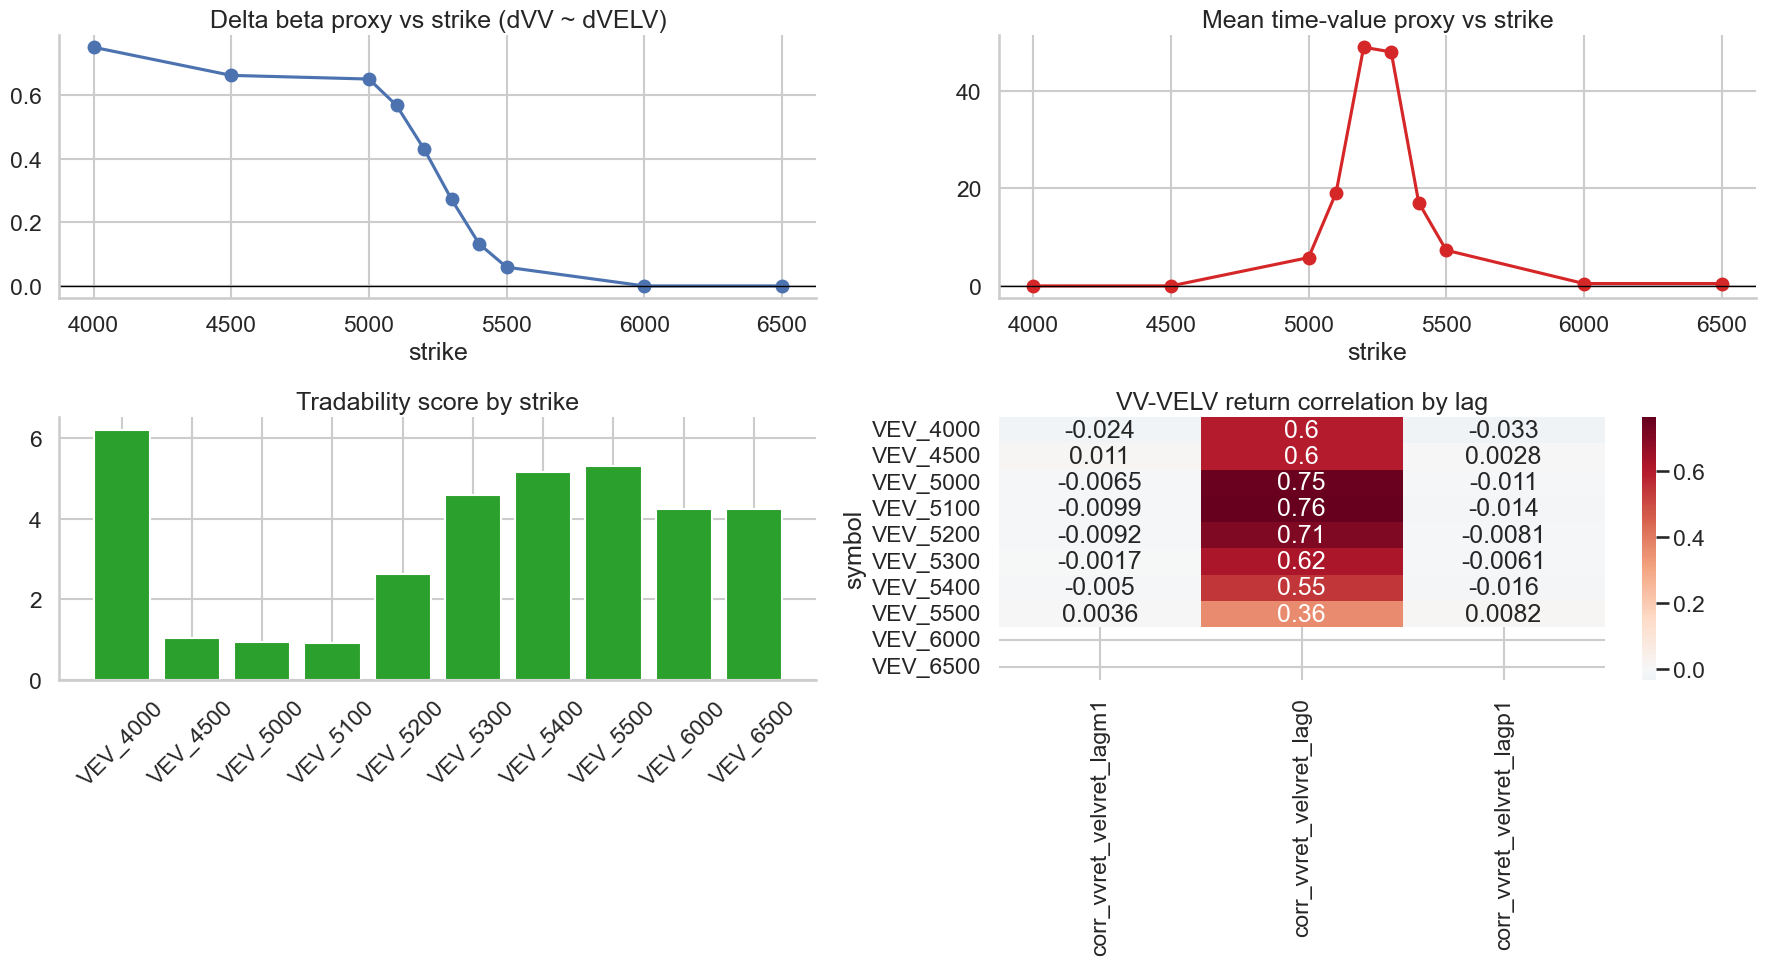

In [4]:
# Pattern views
fig, axes = plt.subplots(2, 2, figsize=(18, 10))

axes[0, 0].plot(joint['strike'], joint['delta_beta_proxy'], marker='o')
axes[0, 0].axhline(0, color='black', lw=1)
axes[0, 0].set_title('Delta beta proxy vs strike (dVV ~ dVELV)')
axes[0, 0].set_xlabel('strike')

axes[0, 1].plot(joint['strike'], joint['mean_time_value_proxy'], marker='o', color='#d62728')
axes[0, 1].axhline(0, color='black', lw=1)
axes[0, 1].set_title('Mean time-value proxy vs strike')
axes[0, 1].set_xlabel('strike')

axes[1, 0].bar(joint['symbol'], joint['tradability_score'], color='#2ca02c')
axes[1, 0].tick_params(axis='x', rotation=45)
axes[1, 0].set_title('Tradability score by strike')

lag_mat = joint[['symbol', 'corr_vvret_velvret_lagm1', 'corr_vvret_velvret_lag0', 'corr_vvret_velvret_lagp1']].set_index('symbol')
sns.heatmap(lag_mat, annot=True, cmap='RdBu_r', center=0, ax=axes[1, 1])
axes[1, 1].set_title('VV-VELV return correlation by lag')

plt.tight_layout()

In [5]:
# Compact auto-findings from the current run
top_trade = joint.sort_values('tradability_score', ascending=False).head(4)
top_beta = joint.sort_values('delta_beta_proxy', ascending=False).head(4)
top_tv = joint.sort_values('mean_time_value_proxy', ascending=False).head(4)
pinned = joint.loc[joint['is_pinned'], ['symbol', 'strike', 'mean_vv_mid', 'std_vv_mid', 'trade_rows']]

print('Top tradability strikes:')
display(top_trade[['symbol', 'strike', 'tradability_score', 'trade_rows', 'imbalance_signal_vv']])

print('Top delta-beta strikes:')
display(top_beta[['symbol', 'strike', 'delta_beta_proxy', 'corr_vvret_velvret_lag0']])

print('Top time-value strikes:')
display(top_tv[['symbol', 'strike', 'mean_time_value_proxy', 'pct_negative_time_value']])

print('Pinned or near-static strikes:')
display(pinned)

Top tradability strikes:


,symbol,strike,tradability_score,trade_rows,imbalance_signal_vv
0,VEV_4000,4000,6.212195,336,0.483653
7,VEV_5500,5500,5.318173,173,0.294642
6,VEV_5400,5400,5.149641,145,0.279123
5,VEV_5300,5300,4.582719,76,0.368897


Top delta-beta strikes:


,symbol,strike,delta_beta_proxy,corr_vvret_velvret_lag0
0,VEV_4000,4000,0.751428,0.597366
1,VEV_4500,4500,0.662905,0.596214
2,VEV_5000,5000,0.651374,0.753024
3,VEV_5100,5100,0.568425,0.764055


Top time-value strikes:


,symbol,strike,mean_time_value_proxy,pct_negative_time_value
4,VEV_5200,5200,48.848175,0.0
5,VEV_5300,5300,47.900850,0.0
3,VEV_5100,5100,19.094375,0.0
6,VEV_5400,5400,17.060725,0.0


Pinned or near-static strikes:


,symbol,strike,mean_vv_mid,std_vv_mid,trade_rows
8,VEV_6000,6000,0.5,0.0,189
9,VEV_6500,6500,0.5,0.0,189


In [6]:
# Optional: export current findings to markdown
report_path = Path('R3/notes/velv_vv_joint_findings.md')
if not report_path.parent.exists():
    report_path = Path('../notes/velv_vv_joint_findings.md')

top_symbols = ', '.join(top_trade['symbol'].tolist())
pinned_symbols = ', '.join(pinned['symbol'].tolist()) if len(pinned) else '(none)'

text = f'''# VELV + VV joint findings

Day 2 is excluded (held out).

## Auto-summary from this notebook run

- Top tradability symbols: {top_symbols}
- Pinned/static symbols: {pinned_symbols}

## Top tradability table

{top_trade[['symbol','strike','tradability_score','trade_rows','imbalance_signal_vv']].to_markdown(index=False)}

## Top delta-beta table

{top_beta[['symbol','strike','delta_beta_proxy','corr_vvret_velvret_lag0']].to_markdown(index=False)}

## Top time-value table

{top_tv[['symbol','strike','mean_time_value_proxy','pct_negative_time_value']].to_markdown(index=False)}
'''

report_path.write_text(text)
print('Wrote:', report_path.resolve())

Wrote: /Users/ericlu/Works/imcp4/imcprosp4/R3/notes/velv_vv_joint_findings.md


## How To Read Patterns

- If `delta_beta_proxy` decreases monotonically with strike, the ladder is behaving option-like against VELV.
- If `corr_vvret_velvret_lag0` dominates lag -1/+1, coupling is mostly contemporaneous (good for same-tick hedging logic).
- If `mean_time_value_proxy` has a hump near middle strikes, near-money options are carrying most time value.
- If a symbol is pinned (`std_vv_mid ~ 0`), avoid expecting directional alpha from it.
- Prioritize strikes with both tradability and a stable VELV linkage.